# 부산광역시 야간조명(NTL)–야간 지표면온도(LST) 분석 (v4)
- 자료: VIIRS 월별 야간조명, MODIS Aqua 야간 LST(MYD11A1.061), MODIS NDVI(MOD13A2.061), SRTM 고도, ESA WorldCover(토지피복·육지/수면)
- 부산 경계: geoBoundaries ADM2(구·군) 16개를 합쳐서 사용
- 분석 단위: MODIS 약 1 km 격자, **같은 연월끼리** 비교 (2022–2025)
- 고려하는 환경변수: **해안까지의 거리, 고도, 토지피복, 식생지수(NDVI)** 4가지만 사용

**연구 질문 ↔ 세부목적 ↔ 코드 셀**
- 세부목적 1 (10번 셀): 환경조건을 고려한 야간조명–야간 LST 관계 (보정 전후 계수, 추정 구간, ΔR²)
- 세부목적 2 (11번 셀): 동일한 환경변수를 적용한 계절별 관계 비교 (계절별 계수, 계절 간 계수 차이와 95% 추정 구간)
- 세부목적 3 (12~13번 셀): 최소 유효 관측 일수 기준(1·3·5·7·10일)을 바꿨을 때 계절별 계수의 민감도

**모형 요약**
- 모든 모형은 **연월 평균을 뺀 값(= 연월 고정효과)** 으로 추정하므로, 계수는 "같은 연월 안에서 격자 간 차이"를 뜻합니다.
- 야간조명 = ln(NTL+1)을 **전체 자료에서 한 번 계산한 SD**로 표준화 → 계수 단위는 °C / 1 SD, 계절·기준 간 직접 비교 가능
- 토지피복: WorldCover 10 m를 1 km 격자 최빈값으로 집계해 3개 유형(시가화지역·농경지·녹지·자연지역)으로 재분류, 더미변수로 투입 (기준범주 = 녹지·자연지역)
- 같은 격자가 여러 연월에 반복 관측되므로 **격자 단위 군집 표준오차** 사용
- 계절: 봄(3–5월), 여름(6–8월), 가을(9–11월), 겨울(12·1·2월, 같은 달력연도 기준)

**사용법**: 위에서부터 순서대로 실행. 1번 셀의 `GEE_PROJECT`만 바꾸면 됩니다.
4번(경계), 6번(시험 추출) 셀은 값이 이상하면 일부러 멈추도록 만들어 두었습니다.

In [3]:
# 1. 설정
import os, re, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.api as sm
from scipy import stats
import ee

GEE_PROJECT    = 'earth-engine-student-2026'   # <- 본인 Google Cloud 프로젝트 ID로 변경
START_YEAR     = 2022                    # 분석 기간 (VIIRS 월별 자료가 있는 구간 안에서 선택)
END_YEAR       = 2025
QA_STRICT      = False                   # False: LST 품질 'good + 보통'까지 사용 (True면 거의 다 버려짐)
MIN_LAND_FRAC  = 0.8                     # 1 km 격자 중 육지 비율이 이 값 이상인 격자만 사용
THRESHOLDS     = [1, 3, 5, 7, 10]        # 최소 유효 관측 수(한 달 중 LST가 유효한 밤의 수) 후보
BASE_MIN_VALID = 3                       # 세부목적 1~2의 기본 기준
FORCE_REEXTRACT = False                  # True면 저장된 CSV를 무시하고 Earth Engine에서 다시 추출

pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.width', 200)

# 한글 폰트 (Colab에서 그래프 한글 깨짐 방지)
try:
    subprocess.run(['apt-get', '-qq', 'update'], check=True, capture_output=True)
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-nanum'], check=True, capture_output=True)
    for p in fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum']):
        fm.fontManager.addfont(p)
    plt.rcParams['font.family'] = 'NanumGothic'
except Exception as e:
    print('한글 폰트 설치 실패(그래프 한글이 깨질 수 있음):', e)
plt.rcParams['axes.unicode_minus'] = False

# 결과 저장 위치: 드라이브 연결에 성공하면 드라이브, 아니면 Colab 임시 폴더
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/busan_ntl_lst'
except Exception as e:
    print('드라이브 연결 실패, 임시 폴더를 사용합니다:', e)
    BASE_DIR = '/content/busan_ntl_lst'
os.makedirs(BASE_DIR, exist_ok=True)
print('저장 폴더:', BASE_DIR)

Mounted at /content/drive
저장 폴더: /content/drive/MyDrive/busan_ntl_lst


In [4]:
# 2. Earth Engine 인증/초기화
ee.Authenticate()
ee.Initialize(project=GEE_PROJECT)
print('Earth Engine 연결 성공:', ee.Number(1).getInfo())

Earth Engine 연결 성공: 1


In [5]:
# 3. 부산 16개 구·군 경계 만들기 (geoBoundaries ADM2)
# 부산 전체 한 덩어리(ADM1)를 바로 쓰면 일부만 잡히는 문제가 있었기 때문에,
# 구·군(ADM2) 16개를 찾아서 합치는 방식으로 바꿨다. (교수님 코드도 같은 자료를 사용)
BOX = [128.70, 34.80, 129.40, 35.45]    # 부산을 넉넉히 덮는 사각형 [경도min, 위도min, 경도max, 위도max]
NAME_DICT = {
    'gangseo': '강서구', 'geumjeong': '금정구', 'gijang': '기장군', 'nam': '남구', 'dong': '동구',
    'dongnae': '동래구', 'busanjin': '부산진구', 'pusanjin': '부산진구', 'buk': '북구', 'sasang': '사상구',
    'saha': '사하구', 'seo': '서구', 'suyeong': '수영구', 'yeonje': '연제구', 'yeongdo': '영도구',
    'jung': '중구', 'haeundae': '해운대구'}
EXPECTED = set(NAME_DICT.values())

def korean_name(name):
    # 대괄호와 그 안의 내용(예: [North Distrikt])을 먼저 지웁니다.
    clean_name = re.sub(r'\[.*?\]', '', str(name))
    key = re.sub(r'[\s_\-]+', '', clean_name.strip().lower())
    key = re.sub(r'(district|county)$', '', key)
    key = re.sub(r'(gun|gu)$', '', key)
    return NAME_DICT.get(key, str(name))

adm2 = (ee.FeatureCollection('WM/geoLab/geoBoundaries/600/ADM2')
        .filter(ee.Filter.eq('shapeGroup', 'KOR'))
        .filterBounds(ee.Geometry.Rectangle(BOX)))

def add_info(f):
    f = ee.Feature(f)
    g = f.geometry()
    c = g.centroid(100).coordinates()
    return f.set({'cx': c.get(0), 'cy': c.get(1), 'area_km2': g.area(100).divide(1e6)})

info = adm2.map(add_info).select(['shapeName', 'shapeID', 'cx', 'cy', 'area_km2'], None, False)
cand = pd.DataFrame([f['properties'] for f in info.getInfo()['features']])
cand['district'] = cand['shapeName'].map(korean_name)
inside = cand['cx'].between(BOX[0], BOX[2]) & cand['cy'].between(BOX[1], BOX[3])
sel = cand[inside & cand['district'].isin(EXPECTED)].copy()

print('사각형 안의 시·군·구 후보:')
print(cand.sort_values('shapeName')[['shapeName', 'district', 'cx', 'cy', 'area_km2']].to_string(index=False))
assert len(sel) == 16 and sel['district'].nunique() == 16, (
    f'부산 구·군이 {len(sel)}개만 잡혔습니다(16개여야 함). 위 후보 표에서 빠진 구·군 이름을 확인하세요.')

districts = adm2.filter(ee.Filter.inList('shapeID', sel['shapeID'].tolist()))
busan = districts.geometry(100)

area_km2 = busan.area(100).getInfo() / 1e6
b = busan.bounds(100).coordinates().getInfo()[0]
lon_rng = (min(p[0] for p in b), max(p[0] for p in b))
lat_rng = (min(p[1] for p in b), max(p[1] for p in b))
print(f'\n부산 경계 면적: {area_km2:.0f} km² | 경도 {lon_rng[0]:.2f}~{lon_rng[1]:.2f} | 위도 {lat_rng[0]:.2f}~{lat_rng[1]:.2f}')
print('구·군별 면적(km²):')
print(sel.sort_values('area_km2', ascending=False)[['district', 'area_km2']].to_string(index=False))
assert 650 < area_km2 < 950, (
    f'면적이 {area_km2:.0f} km²입니다. 부산은 약 770 km²여야 합니다. 위 구·군별 면적에서 이상한 구·군을 확인하세요.')
assert lon_rng[0] < 128.85 and lon_rng[1] > 129.25, '강서구(서쪽) 또는 기장군(동쪽)이 빠진 것 같습니다.'

사각형 안의 시·군·구 후보:
                 shapeName    district      cx     cy  area_km2
   Buk-gu [North Distrikt]          북구 129.024 35.229    40.494
               Busanjin-gu        부산진구 129.042 35.154    21.666
               Changwon-si Changwon-si 128.596 35.209   708.130
   Dong-gu [East District]          동구 129.047 35.128     5.132
                Dongnae-gu         동래구 129.074 35.197    26.736
                Gangseo-gu         강서구 128.907 35.157   133.140
                  Geoje-si    Geoje-si 128.628 34.872   349.043
              Geumjeong-gu         금정구 129.095 35.253    63.219
                Gijang-gun         기장군 129.199 35.292   203.686
                 Gimhae-si   Gimhae-si 128.846 35.267   474.021
               Haeundae-gu        해운대구 129.154 35.190    42.660
Jung-gu [Central District]          중구 129.034 35.112     3.342
                Miryang-si  Miryang-si 128.790 35.494   784.921
   Nam-gu [South District]          남구 129.093 35.128    19.407
                   Saha

In [6]:
# 4. 격자 기준과 고정 변수: 육지 비율, 고도, 해안(수면)까지 거리
# 기준 격자 = MODIS 1 km 격자. 다른 자료는 이 격자로 평균 집계한다.
PROJ = ee.ImageCollection('MODIS/061/MYD11A1').first().select('LST_Night_1km').projection()

def to_grid(img, src_proj=None):
    """해상도가 다른 영상을 MODIS 1 km 격자로 평균 집계"""
    if src_proj is not None:
        img = img.setDefaultProjection(src_proj)
    return img.reduceResolution(reducer=ee.Reducer.mean(), maxPixels=65536).reproject(PROJ)

worldcover = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')
water = worldcover.unmask(80).eq(80)                 # 80 = 영구 수면. 자료가 없는 바다도 수면으로 본다.
land_frac = to_grid(water.Not()).rename('land_frac') # 1 km 격자 안의 육지 비율
elev = to_grid(ee.Image('USGS/SRTMGL1_003').select('elevation')).rename('elev')

# 수면까지 거리: 250 m 격자에서 계산한 뒤 1 km로 집계
# 주의: 큰 하천(낙동강 등)도 수면이라 '가장 가까운 물'까지의 거리에 가깝다.
proj250 = ee.Projection('EPSG:4326').atScale(250)
water_frac250 = water.reduceResolution(ee.Reducer.mean(), maxPixels=4096).reproject(proj250)
sea250 = (water_frac250.gt(0.5)
          .focalMin(radius=3, kernelType='circle', units='pixels')
          .focalMax(radius=3, kernelType='circle', units='pixels'))
dist_m = sea250.distance(ee.Kernel.euclidean(30000, 'meters'))
coast_km = to_grid(dist_m.divide(1000)).rename('coast_km')

# 부산형 3개 토지이용 유형 재분류
# 1 = 시가화지역
# 2 = 농경지
# 3 = 녹지·자연지역
# 7 = 수면(분석 제외)

wc_classes = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]
wc_groups  = [ 3,  3,  3,  2,  1,  3,  3,  7,  3,  3,   3]

landuse_10m = worldcover.remap(
    wc_classes, wc_groups
).rename('landuse')

landuse_1km = (
    landuse_10m
    .reduceResolution(
        reducer=ee.Reducer.mode(),
        maxPixels=65536
    )
    .reproject(PROJ)
    .rename('landuse')
)

In [7]:
# 5. 월별 영상 만들기 + 부산 1 km 격자 값 추출
def mask_lst(img):
    qc = img.select('QC_Night')
    mandatory = qc.bitwiseAnd(3)                       # bit0-1: 0=좋음, 1=보통, 2·3=LST 미생성(구름 등)
    good = mandatory.eq(0) if QA_STRICT else mandatory.lte(1)
    lst = img.select('LST_Night_1km').multiply(0.02).subtract(273.15)   # K -> 섭씨
    return lst.updateMask(good).rename('LST')

def mask_ndvi(img):
    ok = img.select('SummaryQA').lte(1)                # 0 good, 1 marginal
    return img.select('NDVI').multiply(0.0001).updateMask(ok).rename('NDVI')

viirs_all = ee.ImageCollection('NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG').select('avg_rad')
VIIRS_PROJ = viirs_all.first().projection()

def month_stack(year, month):
    start = ee.Date.fromYMD(year, month, 1)
    end = start.advance(1, 'month')
    lst_c = ee.ImageCollection('MODIS/061/MYD11A1').filterDate(start, end).map(mask_lst)
    lst = lst_c.mean().rename('LST')                   # 월평균 야간 LST
    n_valid = lst_c.count().rename('n_valid')          # 월 유효 관측 수
    ntl = to_grid(viirs_all.filterDate(start, end).mean(), VIIRS_PROJ).rename('ntl')
    ndvi = (ee.ImageCollection('MODIS/061/MOD13A2').filterDate(start, end)
            .map(mask_ndvi).mean().rename('NDVI'))     # MYD11A1과 같은 1 km 격자
    return ee.Image.cat([lst, n_valid, ntl, ndvi, elev, coast_km, land_frac, landuse_1km])

def sample_month(year, month, retries=3):
    img = month_stack(year, month)
    # dropNulls=False: 결측이 있어도 격자를 남겨두고 파이썬에서 거른다 (어느 변수가 비는지 보이게)
    fc = img.sample(region=busan, projection=PROJ, geometries=True, dropNulls=False)
    for k in range(retries):
        try:
            info = fc.getInfo()
            break
        except Exception as e:
            print('  재시도', k + 1, e)
    else:
        return []
    rows = []
    for f in info['features']:
        p = dict(f['properties'])
        lon, lat = f['geometry']['coordinates']
        p.update(lon=lon, lat=lat, year=year, month=month)
        rows.append(p)
    return rows

In [8]:
# 6. 시험 추출 (한 달만): 이 결과가 정상이어야 전체 추출로 넘어간다
VARS_CHECK = ['LST', 'n_valid', 'ntl', 'NDVI', 'elev', 'coast_km', 'land_frac', 'landuse']
t = pd.DataFrame(sample_month(2021, 7))
print('2021-07 격자 수:', len(t), '(부산 전체면 대략 800~1000개)')
print('변수별 값이 있는 격자 수:')
print(t[VARS_CHECK].notna().sum())
print('\n수치 요약:')
print(t[VARS_CHECK].describe().T[['count', 'min', 'mean', 'max']])
assert len(t) > 600, '격자가 너무 적습니다. 3번 셀의 경계 출력(면적, 범위)을 다시 확인하세요.'
for v in ['ntl', 'elev', 'coast_km', 'land_frac']:
    assert t[v].notna().mean() > 0.9, f'{v} 값이 대부분 비어 있습니다. 4번 셀을 점검하세요.'
if t['LST'].notna().mean() < 0.3:
    print('경고: LST가 있는 격자가 30% 미만입니다. QA_STRICT=False인지, 영상 수는 충분한지 확인하세요.')

2021-07 격자 수: 768 (부산 전체면 대략 800~1000개)
변수별 값이 있는 격자 수:
LST          758
n_valid      758
ntl          768
NDVI         731
elev         768
coast_km     768
land_frac    768
landuse      768
dtype: int64

수치 요약:
            count    min    mean     max
LST       758.000 15.163  21.490  24.863
n_valid   758.000  1.000   4.612  10.000
ntl       768.000  1.594  19.216 129.644
NDVI      731.000  0.172   0.674   0.946
elev      768.000  0.415 115.226 626.277
coast_km  768.000  0.217   6.942  17.112
land_frac 768.000  0.389   0.959   1.000
landuse   768.000  1.000   2.486   7.000


In [9]:
pts = {'해운대 해수욕장': (129.160, 35.159), '서면': (129.059, 35.158),
       '동래': (129.085, 35.205), '금정산 고당봉': (129.055, 35.283)}
for name, (lo, la) in pts.items():
    i = ((t['lon'] - lo)**2 + (t['lat'] - la)**2).idxmin()
    print(f"{name}: 해안거리 {t.loc[i, 'coast_km']:.2f} km")
print('전체 최대 해안거리:', round(t['coast_km'].max(), 1), 'km')

해운대 해수욕장: 해안거리 0.77 km
서면: 해안거리 3.53 km
동래: 해안거리 6.99 km
금정산 고당봉: 해안거리 16.10 km
전체 최대 해안거리: 17.1 km


In [10]:
# 7. 전체 기간 추출 (몇 분 걸림). 저장 파일이 있고 정상이면 다시 추출하지 않는다.
CSV_PATH = f'{BASE_DIR}/busan_ntl_lst_{START_YEAR}_{END_YEAR}_landuse_v3_qa{int(QA_STRICT)}.csv'

def cache_ok(d):
    return len(d) > 0 and 'landuse' in d.columns and d.groupby(['year', 'month']).size().median() >= 600

raw = None
if os.path.exists(CSV_PATH) and not FORCE_REEXTRACT:
    cached = pd.read_csv(CSV_PATH)
    if cache_ok(cached):
        raw = cached
        print('저장된 파일을 불러왔습니다:', CSV_PATH, raw.shape)
    else:
        print('저장된 파일이 비정상(격자 수 부족)이라 다시 추출합니다.')

if raw is None:
    all_rows = []
    for y in range(START_YEAR, END_YEAR + 1):
        for m in range(1, 13):
            rows = sample_month(y, m)
            all_rows += rows
            n_lst = sum(1 for r in rows if r.get('LST') is not None)
            print(f'{y}-{m:02d}: 격자 {len(rows)}개 (LST 있음 {n_lst})')
    raw = pd.DataFrame(all_rows)
    assert cache_ok(raw), '추출 결과가 비정상입니다(월별 격자 수 부족). 6번 셀 시험 추출부터 다시 확인하세요.'
    raw.to_csv(CSV_PATH, index=False)
    print('저장 완료:', CSV_PATH, raw.shape)

저장된 파일을 불러왔습니다: /content/drive/MyDrive/busan_ntl_lst/busan_ntl_lst_2022_2025_landuse_v3_qa0.csv (36864, 12)


landuse
3    21681
1     9454
2     1584
Name: count, dtype: int64
         land_frac    elev  NDVI    ntl
landuse                                
1            0.978  38.793 0.392 51.088
2            0.959   2.648 0.376 11.565
3            0.990 172.235 0.632 13.440
원본 36864 → 육지 비율 필터 34032 → 결측 제거 32719 행
격자 수: 709 | 연월 수: 48
토지이용 유형별 격자 수:
landuse_type
녹지·자연지역    464
시가화지역      211
농경지         34
dtype: int64
             count    mean     std    min    25%    50%     75%     max
LST      32719.000  10.167   8.535 -7.235  1.778 10.590  18.022  26.028
n_valid  32719.000   9.624   5.077  1.000  6.000  9.000  13.000  27.000
ntl      32719.000  24.227  23.329  0.000  6.568 15.159  35.566 220.848
ln_ntl   32719.000   2.803   0.954  0.000  2.024  2.782   3.599   5.402
NDVI     32719.000   0.550   0.195  0.048  0.399  0.543   0.708   0.981
elev     32719.000 125.467 118.915  0.777 33.849 88.113 186.775 626.277
coast_km 32719.000   6.923   4.127  0.377  3.419  6.431  10.007  17.112
격자 수가 10

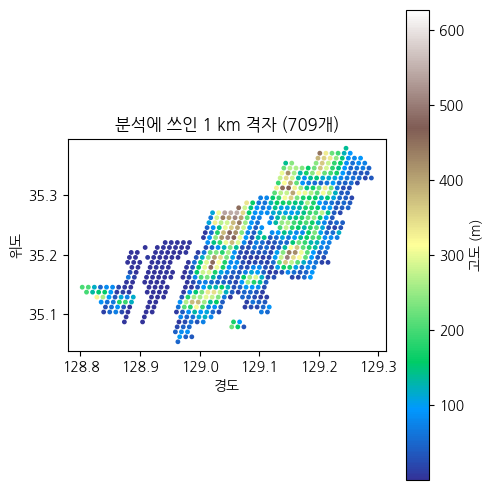

In [11]:
# 8. 전처리
df = raw.copy()
n0 = len(df)
df = df[df['land_frac'] >= MIN_LAND_FRAC]
n1 = len(df)
df = df.dropna(subset=['LST', 'ntl', 'NDVI', 'elev', 'coast_km', 'landuse']).copy()
print(df['landuse'].value_counts(dropna=False))
print(df.groupby('landuse')[['land_frac', 'elev', 'NDVI', 'ntl']].mean().round(3))
n2 = len(df)
print(f'원본 {n0} → 육지 비율 필터 {n1} → 결측 제거 {n2} 행')
assert n2 > 0, '전처리 후 0행입니다. 위 단계별 행 수를 보고 어느 단계에서 사라졌는지 확인하세요.'

df['ym'] = df['year'].astype(int).astype(str) + '-' + df['month'].astype(int).astype(str).str.zfill(2)
df['pid'] = df['lon'].round(5).astype(str) + '_' + df['lat'].round(5).astype(str)
df['pid_code'] = pd.factorize(df['pid'])[0]            # 같은 격자의 반복 관측을 묶는 용도(군집 표준오차)
df['ln_ntl'] = np.log1p(df['ntl'].clip(lower=0))
# ESA WorldCover 최빈 토지피복 코드 -> 분석용 유형명
LANDUSE_LABELS = {
    1: '시가화지역',
    2: '농경지',
    3: '녹지·자연지역'
}
df['landuse_code'] = pd.to_numeric(df['landuse'], errors='coerce')
df = df[df['landuse_code'].isin(LANDUSE_LABELS)].copy()
df['landuse_type'] = df['landuse_code'].astype(int).map(LANDUSE_LABELS)
SEASON = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
          6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
df['season'] = df['month'].astype(int).map(SEASON)

print('격자 수:', df['pid'].nunique(), '| 연월 수:', df['ym'].nunique())
print('토지이용 유형별 격자 수:')
print(df.drop_duplicates('pid').groupby('landuse_type').size().sort_values(ascending=False))
print(df[['LST', 'n_valid', 'ntl', 'ln_ntl', 'NDVI', 'elev', 'coast_km']].describe().T)

# 표본이 너무 적은 달 제외 (구름이 많은 달)
cnt = df.groupby('ym').size()
print('격자 수가 100 미만인 달(제외):\n', cnt[cnt < 100])
df = df[df['ym'].isin(cnt[cnt >= 100].index)].copy()
assert len(df) > 0, '표본이 100격자 이상인 달이 없습니다.'

# 추출된 격자가 부산 전체를 덮는지 눈으로 확인
cells = df.drop_duplicates('pid')
plt.figure(figsize=(5, 5))
plt.scatter(cells['lon'], cells['lat'], s=6, c=cells['elev'], cmap='terrain')
plt.colorbar(label='고도 (m)')
plt.title(f'분석에 쓰인 1 km 격자 ({len(cells)}개)')
plt.xlabel('경도'); plt.ylabel('위도'); plt.gca().set_aspect('equal')
plt.tight_layout(); plt.show()

In [12]:
# 9. 분석 함수
# 핵심 아이디어: "같은 연월 안에서의 공간 차이"만 보기 위해 각 변수에서 연월 평균을 뺀다(demeaning).
# 이렇게 하면 연월 고정효과를 넣은 회귀와 같고, 계수는 '야간조명이 1 SD 높은 격자가 몇 °C 더 따뜻한가'를 뜻한다.
# 환경변수는 해안까지의 거리, 고도, 토지피복, 식생지수(NDVI) 4가지만 쓴다.

MIN_CELLS_PER_YM = 30    # 기준 적용 후 한 달에 격자가 이 값 미만이면 그 달은 제외 (연월 평균이 불안정해지는 것을 막음)
MIN_ROWS = 100           # 계절별 모형을 추정하기 위한 최소 격자·연월 행 수
MIN_YM   = 3             # 계절별 모형을 추정하기 위한 최소 연월 수

# 토지피복 더미변수 (기준범주 = 녹지·자연지역)
df['lu_urban'] = (df['landuse_code'] == 1).astype(float)   # 시가화지역
df['lu_crop']  = (df['landuse_code'] == 2).astype(float)   # 농경지

VARS  = ['LST', 'ln_ntl', 'coast_km', 'elev', 'NDVI', 'lu_urban', 'lu_crop']
ZVARS = ['ln_ntl', 'coast_km', 'elev', 'NDVI']              # 표준화하는 연속형 변수
# 표준화 기준(SD)은 전체 자료에서 한 번만 계산해 계절·기준 간 계수를 같은 단위로 비교
SD = {v: (df[v] - df.groupby('ym')[v].transform('mean')).std() for v in ZVARS}
ENV = ['coast_km_z', 'elev_z', 'NDVI_z', 'lu_urban_d', 'lu_crop_d']

SEASONS = ['Spring', 'Summer', 'Autumn', 'Winter']
SEASON_KR = {'Spring': '봄', 'Summer': '여름', 'Autumn': '가을', 'Winter': '겨울'}

def prep(d):
    d = d.copy()
    for v in VARS:
        d[v + '_d'] = d[v] - d.groupby('ym')[v].transform('mean')
    for v in ZVARS:
        d[v + '_z'] = d[v + '_d'] / SD[v]
    return d

def select_sample(d, min_valid):
    """최소 유효 관측 수 기준을 적용하고, 격자 수가 너무 적은 달은 뺀다."""
    s = d[d['n_valid'] >= min_valid]
    cnt = s.groupby('ym')['pid'].transform('size')
    return s[cnt >= MIN_CELLS_PER_YM].copy()

def ols(d, xs):
    # 상수항 없음(이미 평균을 뺐으므로). 같은 격자의 반복 관측은 군집 표준오차로 처리
    xs = [x for x in xs if d[x].std() > 0]              # 변동이 없는 변수는 자동으로 뺀다
    return sm.OLS(d['LST_d'], d[xs]).fit(cov_type='cluster', cov_kwds={'groups': d['pid_code']})

def fit_set(d):
    d = prep(d)
    m0 = ols(d, ['ln_ntl_z'])                 # 보정 전: 야간조명만
    m1 = ols(d, ENV)                          # 환경변수만
    m2 = ols(d, ['ln_ntl_z'] + ENV)           # 환경변수 + 야간조명
    ci0 = m0.conf_int().loc['ln_ntl_z']
    ci2 = m2.conf_int().loc['ln_ntl_z']
    return dict(n=len(d), n_pixel=d['pid_code'].nunique(), n_ym=d['ym'].nunique(),
                beta_simple=m0.params['ln_ntl_z'], simple_lo=ci0.iloc[0], simple_hi=ci0.iloc[1],
                r2_simple=m0.rsquared,
                beta_adj=m2.params['ln_ntl_z'], ci_lo=ci2.iloc[0], ci_hi=ci2.iloc[1],
                p_adj=m2.pvalues['ln_ntl_z'],
                r2_env=m1.rsquared, r2_full=m2.rsquared, delta_r2=m2.rsquared - m1.rsquared)

base = select_sample(df, BASE_MIN_VALID)
print('기본 분석 표본:', len(base), '행 (유효 관측 수 >=', BASE_MIN_VALID, ')')
assert len(base) > 300, (
    f'기본 표본이 {len(base)}행뿐입니다. BASE_MIN_VALID를 1~2로 낮추거나 QA_STRICT, 분석 기간을 확인하세요.')
print('계절별 표본 (행 / 격자 / 연월):')
print(base.groupby('season').agg(n=('pid', 'size'), n_pixel=('pid_code', 'nunique'), n_ym=('ym', 'nunique'))
      .reindex(SEASONS))

기본 분석 표본: 31222 행 (유효 관측 수 >= 3 )
계절별 표본 (행 / 격자 / 연월):
           n  n_pixel  n_ym
season                     
Spring  7248      709    12
Summer  7568      709    12
Autumn  8038      709    12
Winter  8368      709    12


표본: 격자·연월 31222 행 | 격자 709 개 | 연월 48 개

[야간조명 계수, °C / 1 SD, 95% 군집 신뢰구간]
보정 전: 0.764  (0.714 ~ 0.814)
보정 후: 0.806  (0.729 ~ 0.884),  p = 7.345e-93
부호 유지: True | 보정 후 계수는 보정 전 대비 +5.5% 변화

[설명력]
R²  야간조명만: 0.297 | 환경변수만: 0.238 | 환경변수+야간조명: 0.357
ΔR² (환경변수만 → 야간조명 추가) = 0.1187

[보정 후 모형의 전체 계수] (lu_urban_d=시가화지역, lu_crop_d=농경지; 기준=녹지·자연지역)
             coef  ci_lo  ci_hi     p
ln_ntl_z    0.806  0.729  0.884 0.000
coast_km_z -0.264 -0.314 -0.215 0.000
elev_z      0.250  0.187  0.313 0.000
NDVI_z      0.118  0.059  0.177 0.000
lu_urban_d  0.288  0.112  0.464 0.001
lu_crop_d  -0.145 -0.391  0.100 0.246

VIF (5~10 이상이면 변수 간 겹침이 큼):
 ln_ntl_z     2.780
coast_km_z   1.270
elev_z       2.310
NDVI_z       2.530
lu_urban_d   2.350
lu_crop_d    1.370
dtype: float64

월별 상관계수 요약 (ln NTL vs LST):
       pearson  spearman
count   48.000    48.000
mean     0.554     0.565
min      0.144     0.157
max      0.846     0.846


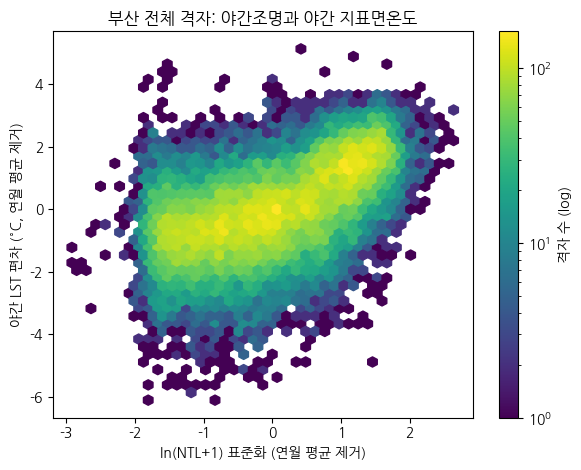

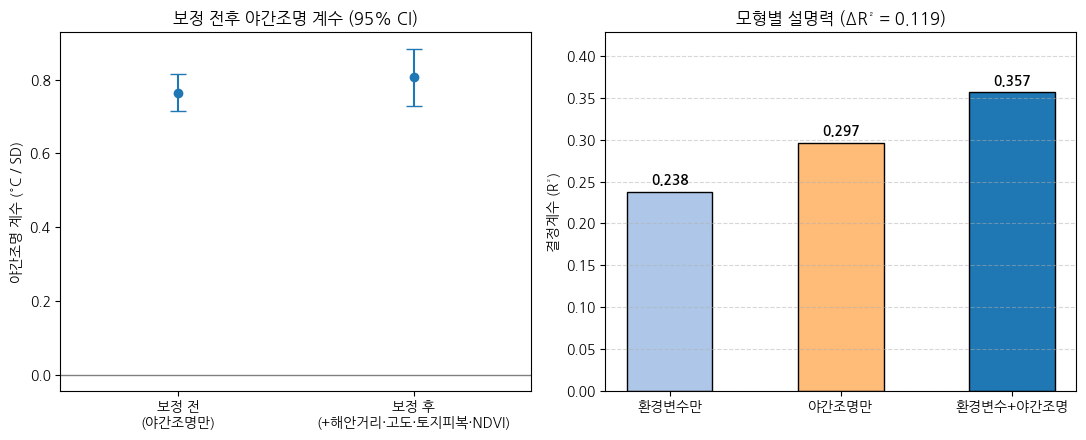

In [13]:
# 10. 세부목적 1: 환경조건을 고려한 야간조명–야간 LST 관계
# ① 같은 격자·연월 표본에서 보정 전(야간조명만) / 보정 후(해안거리·고도·토지피복·NDVI 포함) 계수 비교
# ② 환경변수만 넣은 모형 → 야간조명을 추가한 모형의 R² 증가분(ΔR²)

bd = prep(base)
res = fit_set(base)
so1 = pd.DataFrame([res])
print('표본: 격자·연월', res['n'], '행 | 격자', res['n_pixel'], '개 | 연월', res['n_ym'], '개')

print('\n[야간조명 계수, °C / 1 SD, 95% 군집 신뢰구간]')
print(f"보정 전: {res['beta_simple']:.3f}  ({res['simple_lo']:.3f} ~ {res['simple_hi']:.3f})")
print(f"보정 후: {res['beta_adj']:.3f}  ({res['ci_lo']:.3f} ~ {res['ci_hi']:.3f}),  p = {res['p_adj']:.4g}")
same_sign = np.sign(res['beta_simple']) == np.sign(res['beta_adj'])
change = (res['beta_adj'] - res['beta_simple']) / abs(res['beta_simple']) * 100
print(f"부호 유지: {same_sign} | 보정 후 계수는 보정 전 대비 {change:+.1f}% 변화")

print('\n[설명력]')
print(f"R²  야간조명만: {res['r2_simple']:.3f} | 환경변수만: {res['r2_env']:.3f} | 환경변수+야간조명: {res['r2_full']:.3f}")
print(f"ΔR² (환경변수만 → 야간조명 추가) = {res['delta_r2']:.4f}")

# 환경변수 포함 모형의 전체 계수 (참고)
m_full = ols(bd, ['ln_ntl_z'] + ENV)
coef_tab = pd.DataFrame({'coef': m_full.params, 'ci_lo': m_full.conf_int()[0],
                         'ci_hi': m_full.conf_int()[1], 'p': m_full.pvalues})
print('\n[보정 후 모형의 전체 계수] (lu_urban_d=시가화지역, lu_crop_d=농경지; 기준=녹지·자연지역)')
print(coef_tab.round(4))

from statsmodels.stats.outliers_influence import variance_inflation_factor
X = bd[['ln_ntl_z'] + ENV]
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
print('\nVIF (5~10 이상이면 변수 간 겹침이 큼):\n', vif.round(2))

# 참고: 월별 상관계수 (같은 연월 안에서 NTL과 LST의 상관)
monthly_rows = []
for ym, g in base.groupby('ym'):
    if len(g) < MIN_CELLS_PER_YM:
        continue
    monthly_rows.append({
        'ym': ym, 'n': len(g),
        'pearson': g['ln_ntl'].corr(g['LST']),
        'spearman': stats.spearmanr(g['ln_ntl'], g['LST'])[0]})
monthly = pd.DataFrame(monthly_rows).set_index('ym')
print('\n월별 상관계수 요약 (ln NTL vs LST):')
print(monthly[['pearson', 'spearman']].describe().loc[['count', 'mean', 'min', 'max']].round(3))

# 그림 1: 연월 평균을 제거한 산점도
plt.figure(figsize=(6, 4.8))
plt.hexbin(bd['ln_ntl_z'], bd['LST_d'], gridsize=40, cmap='viridis', mincnt=1, bins='log')
plt.colorbar(label='격자 수 (log)')
plt.xlabel('ln(NTL+1) 표준화 (연월 평균 제거)')
plt.ylabel('야간 LST 편차 (°C, 연월 평균 제거)')
plt.title('부산 전체 격자: 야간조명과 야간 지표면온도')
plt.tight_layout()
plt.show()

# 그림 2: 보정 전후 계수(95% CI)와 R² 비교
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
vals = [res['beta_simple'], res['beta_adj']]
lo = [res['simple_lo'], res['ci_lo']]
hi = [res['simple_hi'], res['ci_hi']]
ax[0].errorbar([0, 1], vals, yerr=[np.array(vals) - np.array(lo), np.array(hi) - np.array(vals)],
               fmt='o', capsize=6, color='tab:blue')
ax[0].axhline(0, color='gray', lw=1)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(['보정 전\n(야간조명만)', '보정 후\n(+해안거리·고도·토지피복·NDVI)'])
ax[0].set_xlim(-0.5, 1.5)
ax[0].set_ylabel('야간조명 계수 (°C / SD)')
ax[0].set_title('보정 전후 야간조명 계수 (95% CI)')

labels = ['환경변수만', '야간조명만', '환경변수+야간조명']
r2s = [res['r2_env'], res['r2_simple'], res['r2_full']]
bars = ax[1].bar(labels, r2s, color=['#aec7e8', '#ffbb78', '#1f77b4'], edgecolor='black', width=0.5)
for b_, h in zip(bars, r2s):
    ax[1].text(b_.get_x() + b_.get_width() / 2, h + 0.005, f'{h:.3f}', ha='center', va='bottom', fontweight='bold')
ax[1].set_ylim(0, max(r2s) * 1.2)
ax[1].set_ylabel('결정계수 (R²)')
ax[1].set_title(f"모형별 설명력 (ΔR² = {res['delta_r2']:.3f})")
ax[1].grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

계절별 결과 (야간조명 계수: °C / 1 SD, 전체 기간 SD 기준)
season_kr    n  n_pixel  n_ym  beta_simple  beta_adj  ci_lo  ci_hi  p_adj  r2_env  r2_full  delta_r2
        봄 7248      709    12        0.845     1.034  0.938  1.129  0.000   0.217    0.365     0.149
       여름 7568      709    12        1.050     0.801  0.718  0.883  0.000   0.451    0.545     0.095
       가을 8038      709    12        0.750     0.833  0.748  0.917  0.000   0.293    0.425     0.132
       겨울 8368      709    12        0.502     0.658  0.566  0.751  0.000   0.221    0.325     0.104

(확인) 교호 모형 계수와 계절별 개별 추정 계수의 최대 차이: 2.33e-15

계절 간 야간조명 계수 차이 (°C / SD, 95% CI)
     비교   diff  ci_lo  ci_hi  p_value
 봄 − 여름  0.233  0.159  0.307    0.000
 봄 − 가을  0.201  0.137  0.265    0.000
 봄 − 겨울  0.375  0.298  0.452    0.000
여름 − 가을 -0.032 -0.099  0.035    0.345
여름 − 겨울  0.142  0.050  0.235    0.003
가을 − 겨울  0.174  0.106  0.243    0.000

계절별 계수 동일성 공동 검정: Wald χ²(3) = 107.27, p = 4.248e-23


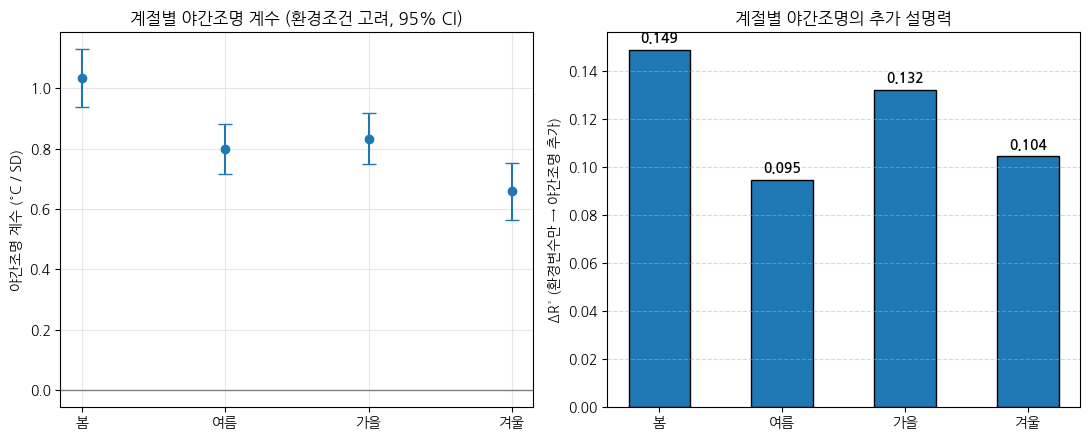

In [14]:
# 11. 세부목적 2: 환경조건을 고려한 계절별 관계 비교
# ① 계절별로 세부목적 1과 같은 모형(해안거리·고도·토지피복·NDVI 포함)을 추정
# ② 계절 간 계수 차이와 95% 신뢰구간 (모든 변수를 계절과 교호시킨 하나의 모형에서 계산 → 같은 격자의 공분산 반영)
from itertools import combinations

season_rows = []
for s in SEASONS:
    d = base[base['season'] == s]
    if len(d) < MIN_ROWS or d['ym'].nunique() < MIN_YM:
        print(SEASON_KR[s], ': 표본 부족으로 제외 (행', len(d), ', 연월', d['ym'].nunique(), ')')
        continue
    r = fit_set(d)
    r['season'] = s
    season_rows.append(r)

so2 = pd.DataFrame(season_rows)
assert len(so2) > 0, '계절별 모형을 추정할 표본이 없습니다.'
so2['season_kr'] = so2['season'].map(SEASON_KR)
seasons_ok = so2['season'].tolist()

print('계절별 결과 (야간조명 계수: °C / 1 SD, 전체 기간 SD 기준)')
print(so2[['season_kr', 'n', 'n_pixel', 'n_ym', 'beta_simple', 'beta_adj', 'ci_lo', 'ci_hi', 'p_adj',
           'r2_env', 'r2_full', 'delta_r2']].round(4).to_string(index=False))

# ── 계절 간 계수 차이 ──
bs = prep(base[base['season'].isin(seasons_ok)])
cols = ['ln_ntl_z'] + ENV
X = pd.DataFrame(index=bs.index)
for s in seasons_ok:
    msk = (bs['season'] == s).astype(float)
    for c in cols:
        X[f'{s}__{c}'] = bs[c] * msk
X = X.loc[:, X.std() > 0]
m_all = sm.OLS(bs['LST_d'], X).fit(cov_type='cluster', cov_kwds={'groups': bs['pid_code']})

# 확인: 교호 모형의 계절별 계수 = 위에서 따로 추정한 계수
chk = max(abs(m_all.params[f'{s}__ln_ntl_z'] - so2.set_index('season').loc[s, 'beta_adj']) for s in seasons_ok)
print(f'\n(확인) 교호 모형 계수와 계절별 개별 추정 계수의 최대 차이: {chk:.2e}')

zcrit = stats.norm.ppf(0.975)
cov = m_all.cov_params()
diff_rows = []
for a, b in combinations(seasons_ok, 2):
    pa, pb = f'{a}__ln_ntl_z', f'{b}__ln_ntl_z'
    est = m_all.params[pa] - m_all.params[pb]
    se = np.sqrt(cov.loc[pa, pa] + cov.loc[pb, pb] - 2 * cov.loc[pa, pb])
    diff_rows.append({'비교': f'{SEASON_KR[a]} − {SEASON_KR[b]}', 'diff': est, 'ci_lo': est - zcrit * se,
                      'ci_hi': est + zcrit * se, 'p_value': 2 * stats.norm.sf(abs(est / se))})
so2_diff = pd.DataFrame(diff_rows)
print('\n계절 간 야간조명 계수 차이 (°C / SD, 95% CI)')
print(so2_diff.round(4).to_string(index=False))

# 모든 계절의 계수가 같은지에 대한 공동 검정 (Wald)
if len(seasons_ok) > 1:
    names = [f'{s}__ln_ntl_z' for s in seasons_ok]
    bvec = m_all.params[names].values
    V = cov.loc[names, names].values
    R = np.zeros((len(names) - 1, len(names)))
    for i in range(len(names) - 1):
        R[i, i], R[i, i + 1] = 1, -1
    wald = float((R @ bvec) @ np.linalg.inv(R @ V @ R.T) @ (R @ bvec))
    p_wald = stats.chi2.sf(wald, df=R.shape[0])
    print(f'\n계절별 계수 동일성 공동 검정: Wald χ²({R.shape[0]}) = {wald:.2f}, p = {p_wald:.4g}')

# 그림: 계절별 계수(95% CI)와 ΔR²
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
x = np.arange(len(so2))
ax[0].errorbar(x, so2['beta_adj'], yerr=[so2['beta_adj'] - so2['ci_lo'], so2['ci_hi'] - so2['beta_adj']],
               fmt='o', capsize=5)
ax[0].axhline(0, color='gray', lw=1)
ax[0].set_xticks(x); ax[0].set_xticklabels(so2['season_kr'])
ax[0].set_ylabel('야간조명 계수 (°C / SD)')
ax[0].set_title('계절별 야간조명 계수 (환경조건 고려, 95% CI)')
ax[0].grid(alpha=0.3)

ax[1].bar(so2['season_kr'], so2['delta_r2'], color='#1f77b4', edgecolor='black', width=0.5)
for xi, h in zip(x, so2['delta_r2']):
    ax[1].text(xi, h + 0.002, f'{h:.3f}', ha='center', va='bottom', fontweight='bold')
ax[1].set_ylabel('ΔR² (환경변수만 → 야간조명 추가)')
ax[1].set_title('계절별 야간조명의 추가 설명력')
ax[1].grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [15]:
# 12. 세부목적 3: 최소 유효 관측 일수 기준에 대한 계절별 민감도
# 기준(THRESHOLDS)마다 표본을 다시 고르고, 세부목적 2와 같은 모형·같은 야간조명 척도(SD)로 계절별 계수를 다시 추정한다.
print('적용 기준(최소 유효 관측 일수):', THRESHOLDS)

sens_rows = []
for t_ in THRESHOLDS:
    dt = select_sample(df, t_)
    for s in SEASONS:
        d = dt[dt['season'] == s]
        if len(d) < MIN_ROWS or d['ym'].nunique() < MIN_YM:
            print(f'기준 {t_}일 · {SEASON_KR[s]}: 표본 부족으로 제외 (행 {len(d)}, 연월 {d["ym"].nunique()})')
            continue
        r = fit_set(d)
        r.update(min_valid=t_, season=s)
        sens_rows.append(r)

sens = pd.DataFrame(sens_rows)
assert len(sens) > 0, '민감도 분석을 수행할 표본이 없습니다.'
sens['season_kr'] = sens['season'].map(SEASON_KR)
sens['season'] = pd.Categorical(sens['season'], categories=SEASONS, ordered=True)
sens = sens.sort_values(['season', 'min_valid']).reset_index(drop=True)

# 기본 기준(BASE_MIN_VALID) 대비 계수 변화
base_beta = sens[sens['min_valid'] == BASE_MIN_VALID].set_index('season')['beta_adj']
sens['beta_change_vs_base'] = sens['beta_adj'] - sens['season'].map(base_beta).astype(float)

print('\n계절 × 기준별 결과 (야간조명 계수: °C / SD)')
print(sens[['season_kr', 'min_valid', 'n', 'n_pixel', 'n_ym', 'beta_adj', 'ci_lo', 'ci_hi',
            'beta_change_vs_base', 'delta_r2']].round(4).to_string(index=False))

# 계절별 요약: 기준을 바꿨을 때 계수의 부호·크기가 얼마나 달라지는지
summ_rows = []
for s, g in sens.groupby('season', observed=True):
    ref = base_beta.get(s, np.nan)
    summ_rows.append({
        'season_kr': SEASON_KR[s],
        'n_criteria': len(g),
        'beta_min': g['beta_adj'].min(), 'beta_max': g['beta_adj'].max(),
        'beta_range': g['beta_adj'].max() - g['beta_adj'].min(),
        'max_abs_change_vs_base': g['beta_change_vs_base'].abs().max(),
        'sign_kept': bool((np.sign(g['beta_adj']) == np.sign(ref)).all()) if np.isfinite(ref) else np.nan,
        'ci_excludes_zero_all': bool(((g['ci_lo'] > 0) | (g['ci_hi'] < 0)).all()),
        'n_min': g['n'].min(), 'n_max': g['n'].max(),
        'delta_r2_min': g['delta_r2'].min(), 'delta_r2_max': g['delta_r2'].max()})
sens_summary = pd.DataFrame(summ_rows)
print(f'\n계절별 민감도 요약 (기본 기준 = {BASE_MIN_VALID}일)')
print(sens_summary.round(4).to_string(index=False))

적용 기준(최소 유효 관측 일수): [1, 3, 5, 7, 10]

계절 × 기준별 결과 (야간조명 계수: °C / SD)
season_kr  min_valid    n  n_pixel  n_ym  beta_adj  ci_lo  ci_hi  beta_change_vs_base  delta_r2
        봄          1 8165      709    12     1.042  0.948  1.135                0.008     0.132
        봄          3 7248      709    12     1.034  0.938  1.129                0.000     0.149
        봄          5 5944      709    11     1.150  1.054  1.246                0.116     0.199
        봄          7 4472      677    11     1.226  1.124  1.328                0.192     0.258
        봄         10 2783      467    11     1.345  1.226  1.464                0.312     0.320
       여름          1 7959      709    12     0.767  0.682  0.851               -0.034     0.080
       여름          3 7568      709    12     0.801  0.718  0.883                0.000     0.095
       여름          5 6015      709    12     0.804  0.721  0.888                0.004     0.115
       여름          7 4049      692    12     0.828  0.739  0.917   

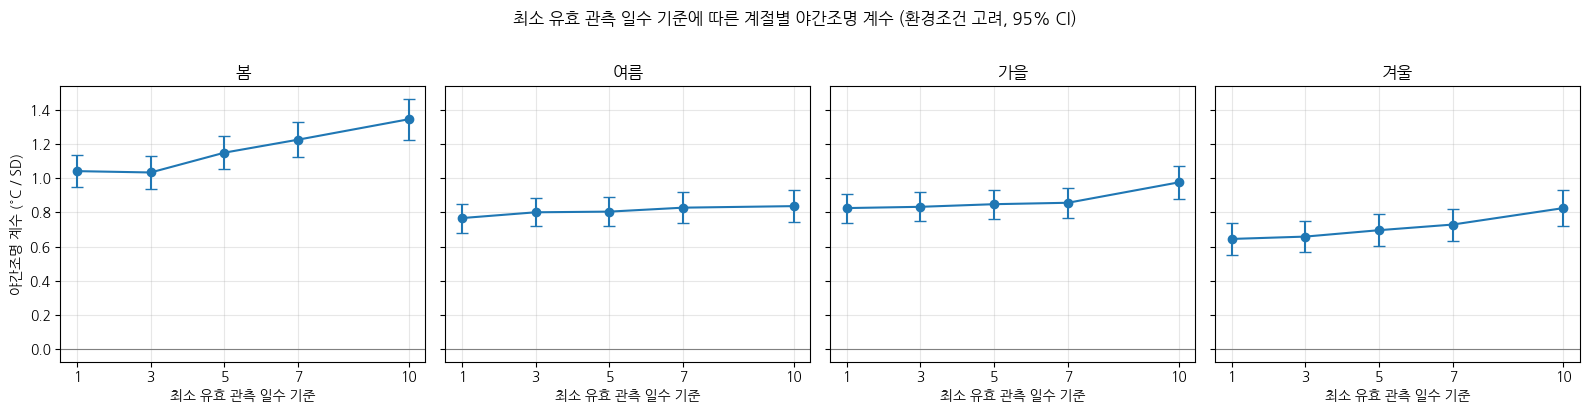

기준별 격자·연월 표본 수
season_kr     봄    여름    가을    겨울
min_valid                        
1          8165  7959  8166  8429
3          7248  7568  8038  8368
5          5944  6015  7416  8028
7          4472  4049  6160  7425
10         2783  1902  4206  6006


In [16]:
# 13. 최소 유효 관측 일수 기준별 계절 야간조명 계수 및 95% CI
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, s in zip(axes, SEASONS):
    g = sens[sens['season'] == s]
    ax.set_title(SEASON_KR[s])
    if len(g):
        ax.errorbar(g['min_valid'], g['beta_adj'],
                    yerr=[g['beta_adj'] - g['ci_lo'], g['ci_hi'] - g['beta_adj']],
                    fmt='o-', capsize=4)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xticks(THRESHOLDS)
    ax.set_xlabel('최소 유효 관측 일수 기준')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('야간조명 계수 (°C / SD)')
fig.suptitle('최소 유효 관측 일수 기준에 따른 계절별 야간조명 계수 (환경조건 고려, 95% CI)', y=1.02)
plt.tight_layout()
plt.show()

# 기준별 표본 수 (기준이 엄격해질수록 표본이 얼마나 줄어드는지)
n_tab = sens.pivot(index='min_valid', columns='season_kr', values='n')[[SEASON_KR[s] for s in SEASONS if SEASON_KR[s] in sens['season_kr'].values]]
print('기준별 격자·연월 표본 수')
print(n_tab)

In [17]:
# 14. 결과 저장
# 세부목적 1
so1.to_csv(f'{BASE_DIR}/result_so1_overall.csv', index=False)
coef_tab.to_csv(f'{BASE_DIR}/result_so1_full_model_coef.csv')
monthly.to_csv(f'{BASE_DIR}/result_monthly_corr.csv')

# 세부목적 2
so2.to_csv(f'{BASE_DIR}/result_so2_season.csv', index=False)
so2_diff.to_csv(f'{BASE_DIR}/result_so2_season_diff.csv', index=False)

# 세부목적 3
sens.to_csv(f'{BASE_DIR}/result_so3_sensitivity.csv', index=False)
sens_summary.to_csv(f'{BASE_DIR}/result_so3_summary.csv', index=False)

print('결과 저장 완료:', BASE_DIR)

결과 저장 완료: /content/drive/MyDrive/busan_ntl_lst
